In [21]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt



def equation(t, y):
    x = y[0]
    v = y[1]

    return [v, -x]
solution = solve_ivp(
    equation,
    t_span=(0, 10),
    y0=[1,0],
    method="RK45"
)

print(solution.t)
print()
print(solution.y)

[0.00000000e+00 9.99000999e-04 1.09890110e-02 1.10889111e-01
 7.60150558e-01 1.69346562e+00 2.68189213e+00 3.66249862e+00
 4.57787220e+00 5.57710241e+00 6.53562405e+00 7.50732249e+00
 8.49647637e+00 9.42948990e+00 1.00000000e+01]

[[ 1.00000000e+00  9.99999501e-01  9.99939621e-01  9.93858100e-01
   7.24709764e-01 -1.22607648e-01 -8.96412983e-01 -8.66881284e-01
  -1.33005579e-01  7.61809510e-01  9.67792753e-01  3.37808419e-01
  -6.01037671e-01 -9.99858424e-01 -8.37545242e-01]
 [ 0.00000000e+00 -9.99000833e-04 -1.09887898e-02 -1.10661995e-01
  -6.89037713e-01 -9.92423098e-01 -4.43138753e-01  4.98428062e-01
   9.91048308e-01  6.47700170e-01 -2.51430149e-01 -9.41118675e-01
  -7.99102741e-01  7.31642727e-03  5.46146478e-01]]


In [97]:
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

def equation(t, y):

    x = y[0]
    v = y[1]

    dxdt = v
    dvdt = -x

    return [dxdt, dvdt]

t_eval=np.linespace
solution = solve_ivp(
    equation,
    t_span=(0, 20),
    y0=[1, 0],
    t_eval=t_eval,
    method="RK45"
)
plt.plot(solution.t, solution.y[0], label="x(t)")
#plt.plot(solution.t, solution.y[1], label="v(t)")

plt.xlabel("t")
plt.ylabel("Value")
plt.legend()
plt.grid()
plt.show()

ValueError: Values in `t_eval` are not within `t_span`.

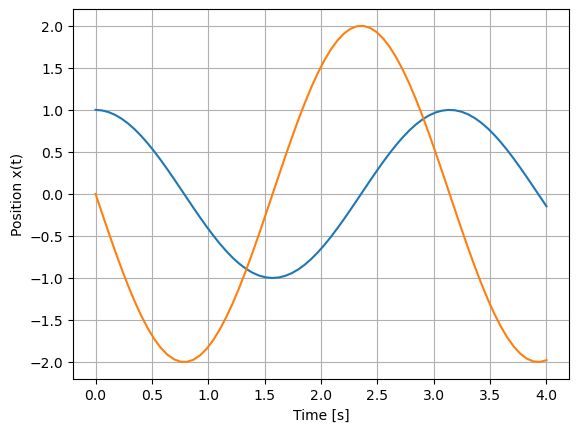

In [35]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt


m = 2.0
k = 8.0


def equation(t, y):

    x = y[0]
    v = y[1]

    dxdt = v
    dvdt = -(k / m) * x

    return [dxdt, dvdt]


def stop_at_x_02(t, y):

    x = y[0]

    return x - 2.8


stop_at_x_02.terminal = True
stop_at_x_02.direction = -1


x0 = 1.0
v0 = 0.0


t_eval = np.linspace(0, 4, 70)


solution = solve_ivp(
    equation,
    t_span=(0, 4),
    y0=[x0, v0],
    events=stop_at_x_02,
    method="RK45",
    t_eval=t_eval
)


plt.plot(solution.t, solution.y[0])
plt.plot(solution.t, solution.y[1])

plt.xlabel("Time [s]")
plt.ylabel("Position x(t)")
plt.grid(0.25)
plt.show()

In [119]:
from ctypes import CDLL, POINTER, c_double
from pathlib import Path
import numpy as np

from scipy.integrate import solve_ivp

In [120]:
lib = CDLL("./libequations.dylib")

In [121]:
lib.equations.argtypes = [
    POINTER(c_double),  # varst
    POINTER(c_double),  # diffs
    c_double,           # impact_par
    POINTER(c_double),  # parbh
]

lib.equations.restype = None

In [122]:
def equations(
    varst: np.ndarray,
    impact_par: float,
    parbh: np.ndarray,
) -> np.ndarray:

    varst = np.ascontiguousarray(varst, dtype=np.float64)
    parbh = np.ascontiguousarray(parbh, dtype=np.float64)

    diffs = np.zeros_like(varst, dtype=np.float64)

    lib.equations(
        varst.ctypes.data_as(POINTER(c_double)),
        diffs.ctypes.data_as(POINTER(c_double)),
        c_double(impact_par),
        parbh.ctypes.data_as(POINTER(c_double)),
    )

    return diffs

In [123]:
varst = np.array([1.0, 2.0, 3.0, 4.0, 5.0])

parbh = np.array([1.0, 0.1])

impact_par = 0.11

diffs = equations(
    varst,
    impact_par,
    parbh
)

print(diffs)

[  3.           4.         -23.85449001 -24.00669752   0.13303955]


In [124]:
def geodesic(lam, varst):

    return equations(
        varst,
        impact_par,
        parbh
    )
    

def hit_disk(lam, varst):

    theta = varst[1]

    return theta - np.pi/2



hit_disk.terminal = True
hit_disk.direction = 1

t_eval = np.linspace(0, 63.8, 100)

varst0 = np.array([
    10000.0,  # r
    0.5,      # theta
    0.0,     # dr/dlambda
    0.001,     # dtheta/dlambda
    0.0       # phi
])

parbh = np.array([1.0, 0.5])

impact_par = 0.11

solution = solve_ivp(
    fun=geodesic,
    t_span=(0.0, 10000.0),
    y0=varst0,
    method="RK45",
    events=hit_disk,
    t_eval=t_eval
)

print(solution.t_events)
hit_state = solution.y_events[0][0]
print(hit_state)

[array([1829.36163831])]
[2.08330566e+04 1.57079633e+00 8.75800871e+00 2.30334471e-04
 2.01274681e-06]


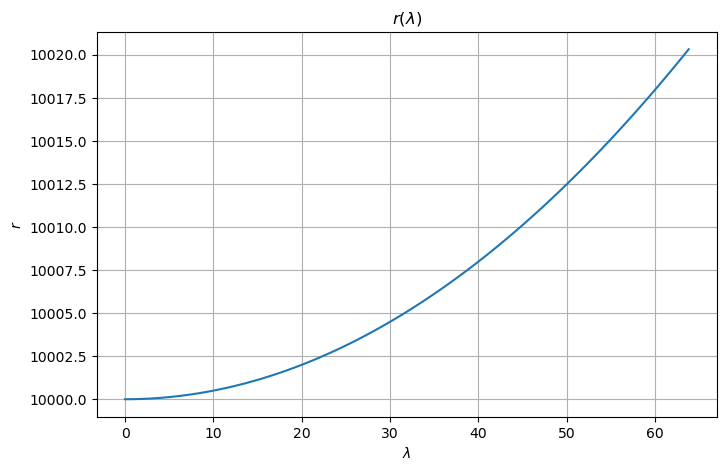

In [125]:
import matplotlib.pyplot as plt

lam = solution.t
r = solution.y[0]

plt.figure(figsize=(8, 5))
plt.plot(lam, r)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$r$")
plt.title(r"$r(\lambda)$")
plt.grid()
plt.show()

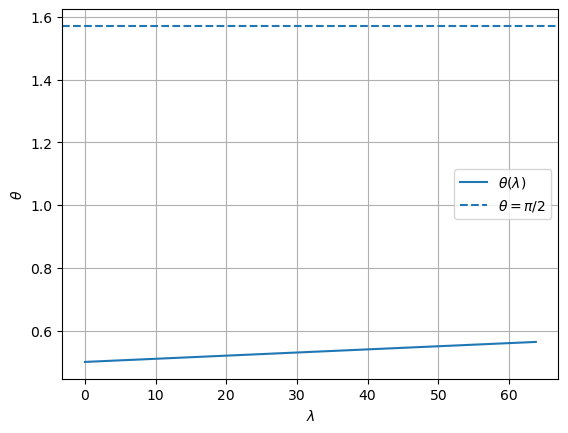

In [126]:
plt.plot(solution.t, solution.y[1], label=r"$\theta(\lambda)$")

plt.axhline(
    np.pi/2,
    linestyle="--",
    label=r"$\theta=\pi/2$"
)

plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\theta$")
plt.legend()
plt.grid()
plt.show()

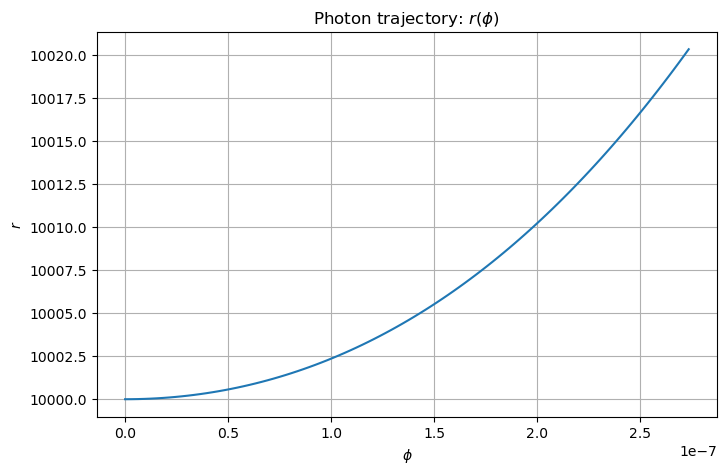

In [130]:
phi=solution.y[4]
plt.figure(figsize=(8, 5))
plt.plot(phi, r)
plt.xlabel(r"$\phi$")
plt.ylabel(r"$r$")
plt.title(r"Photon trajectory: $r(\phi)$")
plt.grid()
plt.show()

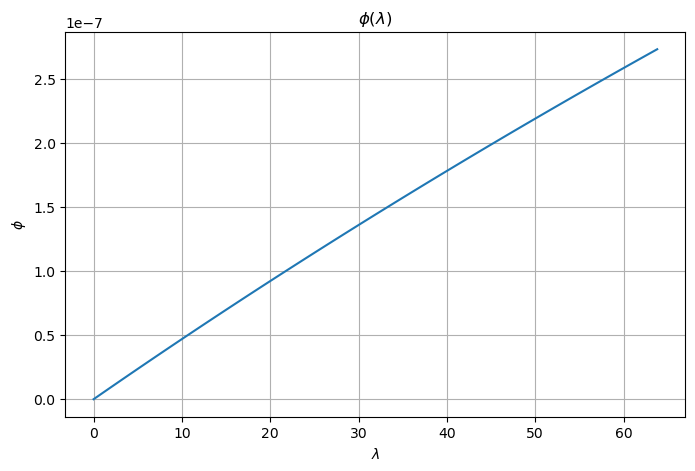

In [131]:
phi = solution.y[4]

plt.figure(figsize=(8, 5))
plt.plot(lam, phi)
plt.xlabel(r"$\lambda$")
plt.ylabel(r"$\phi$")
plt.title(r"$\phi(\lambda)$")
plt.grid()
plt.show()

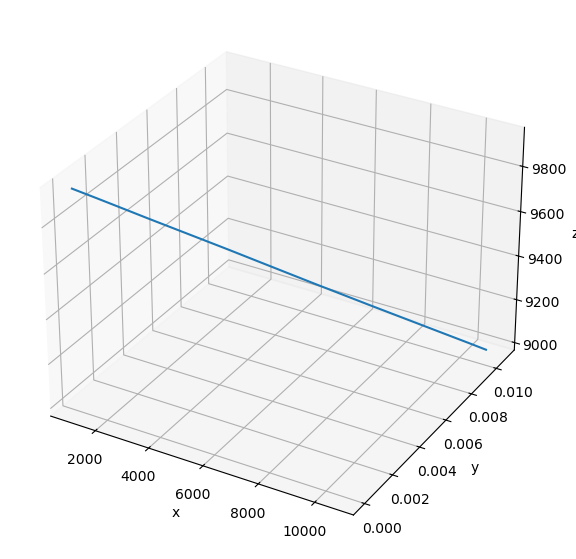

In [100]:
from mpl_toolkits.mplot3d import Axes3D

theta = solution.y[1]
phi = solution.y[4]

x = r * np.sin(theta) * np.cos(phi)
y = r * np.sin(theta) * np.sin(phi)
z = r * np.cos(theta)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.show()

In [101]:
theta_values = np.linspace(0.8, 1.2, 5)

solutions = []

for theta0 in theta_values:

    varst0 = np.array([
        10000.0,
        theta0,
        -1.0,
        0.01,
        0.0
    ])

    solution = solve_ivp(
        geodesic,
        t_span=(0.0, 10000.0),
        y0=varst0,
        method="RK45",
        events=hit_disk,
        t_eval=t_eval
    )

    solutions.append(solution)

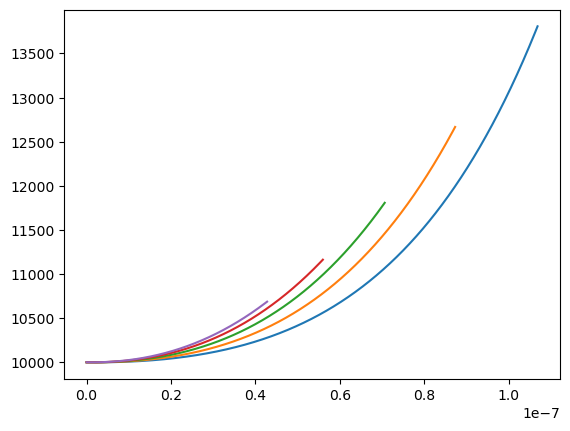

In [118]:
for solution in solutions:

    r = solution.y[0]
    theta = solution.y[1]
    phi = solution.y[4]

    x = r * np.sin(theta) * np.cos(phi)
    y = r * np.sin(theta) * np.sin(phi)
    z = r * np.cos(theta)

    plt.plot(solution.y[4], solution.y[0])